In [74]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [75]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import yfinance as yf
import matplotlib.pyplot as plt

df = yf.download("^GSPC", start="2000-01-01" , auto_adjust=False)

df['Year'] = df.index.year
df['Month'] = df.index.month
df['Day'] = df.index.day

df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Day_sin'] = np.sin(2 * np.pi * df['Day'] / 31)

df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)
df['Day_cos'] = np.cos(2 * np.pi * df['Day'] / 31)

scaler = MinMaxScaler()
df['Year_normal'] = scaler.fit_transform(df[['Year']])

df['Open_diff1'] = df['Open'].diff()
df['Close_diff1'] = df['Close'].diff()
df['Low_diff1'] = df['Low'].diff()
df['High_diff1'] = df['High'].diff()
df = df.dropna().copy()

[*********************100%***********************]  1 of 1 completed


In [76]:
sm.tsa.stattools.acf(df['Open'])

array([1.        , 0.99901146, 0.99803875, 0.99706357, 0.99610603,
       0.99518479, 0.99426879, 0.99334907, 0.99241957, 0.99147266,
       0.990515  , 0.98956243, 0.98861952, 0.98766976, 0.98670685,
       0.98574859, 0.98480449, 0.98387354, 0.98293716, 0.98200153,
       0.98106261, 0.9801314 , 0.97921811, 0.97833878, 0.97747903,
       0.97657332, 0.9757048 , 0.97483707, 0.97394694, 0.97305871,
       0.97211983, 0.97116766, 0.97024768, 0.96933408, 0.96844793,
       0.9675339 , 0.96662467, 0.9657056 , 0.96474945])

In [77]:
sm.tsa.stattools.pacf(df['Open'])

array([ 1.00000000e+00,  9.99164355e-01,  8.90549181e-03, -1.94839120e-03,
        9.96672446e-03,  2.13987997e-02,  2.99247114e-03, -2.65401638e-03,
       -5.99188864e-03, -1.05424978e-02, -7.08455234e-03,  2.19708717e-03,
        4.83357382e-03, -5.17640789e-03, -8.81462872e-03,  2.36770600e-03,
        8.33342874e-03,  7.34804714e-03, -3.91903771e-03,  6.16931502e-06,
       -2.01344973e-03,  4.47852410e-03,  1.04287593e-02,  1.99734745e-02,
        1.12679123e-02, -2.78682780e-02,  2.23172337e-02,  1.91088649e-03,
       -1.41182349e-02, -8.16292534e-04, -3.08256736e-02, -9.65672875e-03,
        1.81813853e-02,  3.38534360e-03,  1.45942758e-02, -1.78174763e-02,
        2.66644984e-03, -4.43848986e-03, -2.13263054e-02])

In [78]:
sm.tsa.stattools.acf(df['Open_diff1'].dropna())

array([ 1.00000000e+00, -2.56935301e-02,  3.87445630e-02, -4.49113587e-02,
       -2.84793085e-02,  9.00302292e-04, -1.78332126e-02,  2.91693589e-02,
       -6.69587546e-03,  6.57825012e-03,  7.76004356e-03, -1.43742532e-03,
        1.02031497e-02,  2.42515338e-03, -1.24620997e-02, -4.08606019e-02,
        1.03471946e-02, -1.58522142e-03,  8.80084494e-03,  4.28048106e-03,
        7.72960820e-03,  4.22374499e-02, -3.73268283e-02,  2.18295200e-02,
       -4.72048669e-02,  4.55144240e-03, -2.34356207e-02, -6.45271429e-03,
        2.94981847e-02, -5.56305027e-03, -1.05969085e-03, -4.55311479e-02,
        1.04585782e-02,  1.71315826e-04, -9.11484708e-03,  4.11088473e-03,
        7.92137452e-03,  1.08690056e-02, -1.13535967e-03])

In [79]:
sm.tsa.stattools.pacf(df['Open_diff1'].dropna())

array([ 1.00000000e+00, -2.56974624e-02,  3.81212384e-02, -4.30854146e-02,
       -3.22046206e-02,  2.80760362e-03, -1.74781453e-02,  2.56393905e-02,
       -4.81068157e-03,  2.76090057e-03,  9.90037291e-03, -2.32761110e-04,
        9.28809364e-03,  5.00793684e-03, -1.36568416e-02, -4.08263774e-02,
        1.03909617e-02,  5.80518337e-04,  4.09471694e-03,  2.76353888e-03,
        7.46545230e-03,  4.27080330e-02, -3.34002961e-02,  1.71336124e-02,
       -3.91497767e-02,  6.81711778e-04, -2.07733212e-02, -8.58488095e-03,
        2.55277905e-02, -3.99887488e-03, -9.88154739e-03, -4.13581009e-02,
        9.73948903e-03,  3.54967748e-03, -1.16451658e-02,  2.00512106e-03,
        1.32770849e-02,  6.75212881e-03,  1.17272896e-03])

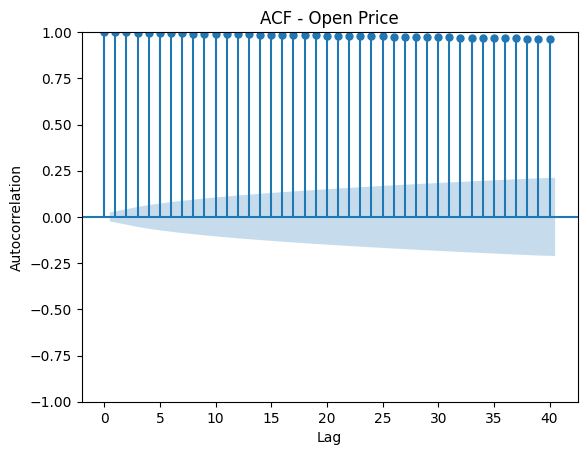

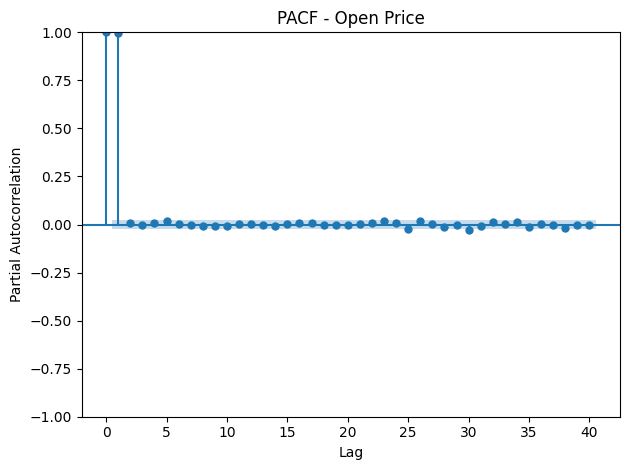

In [80]:
def plot_acf_pacf(x):
  sm.graphics.tsa.plot_acf(x, lags=40)
  plt.title('ACF - Open Price')
  plt.xlabel('Lag')
  plt.ylabel('Autocorrelation')

  sm.graphics.tsa.plot_pacf(x, lags=40, method='ywm')
  plt.title('PACF - Open Price')
  plt.xlabel('Lag')
  plt.ylabel('Partial Autocorrelation')

  plt.tight_layout()
  plt.show()
plot_acf_pacf(df['Open'])

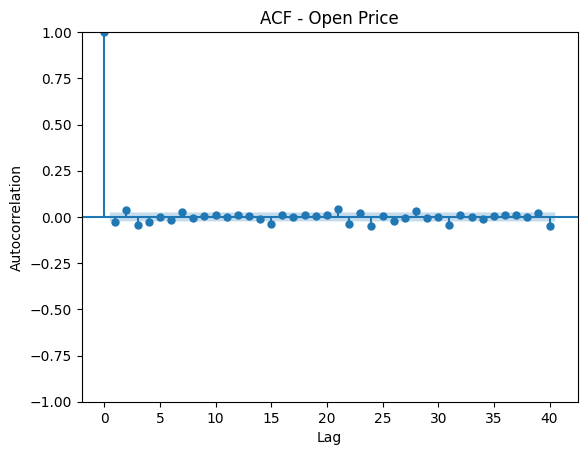

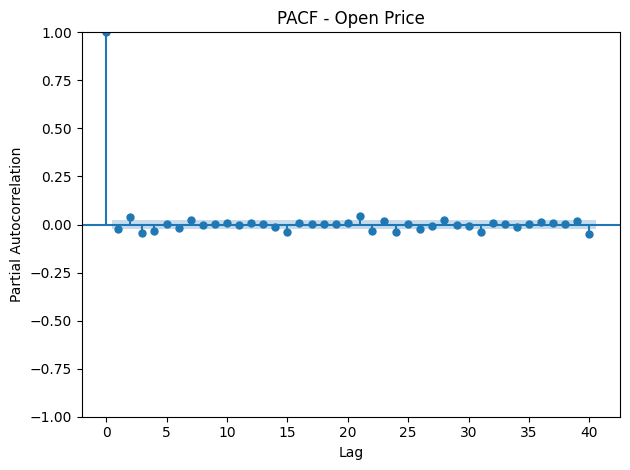

In [81]:
plot_acf_pacf(df['Open_diff1'])

In [82]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['Open_diff1'])

print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -15.538708989432962
p-value: 2.173268007769989e-28


In [83]:
def is_ergodic(series, n_splits=5, tol=0.05):
    split_size = len(series) // n_splits
    means = []
    vars_ = []

    for i in range(n_splits):
        part = series[i*split_size:(i+1)*split_size]
        means.append(part.mean())
        vars_.append(part.var())

    mean_diff = max(means) - min(means)
    var_diff = max(vars_) - min(vars_)

    mean_tol = tol * series.mean()
    var_tol = tol * series.var()

    return (mean_diff <= mean_tol) and (var_diff <= var_tol)

is_ergodic(df['Open_diff1'].dropna())

np.False_

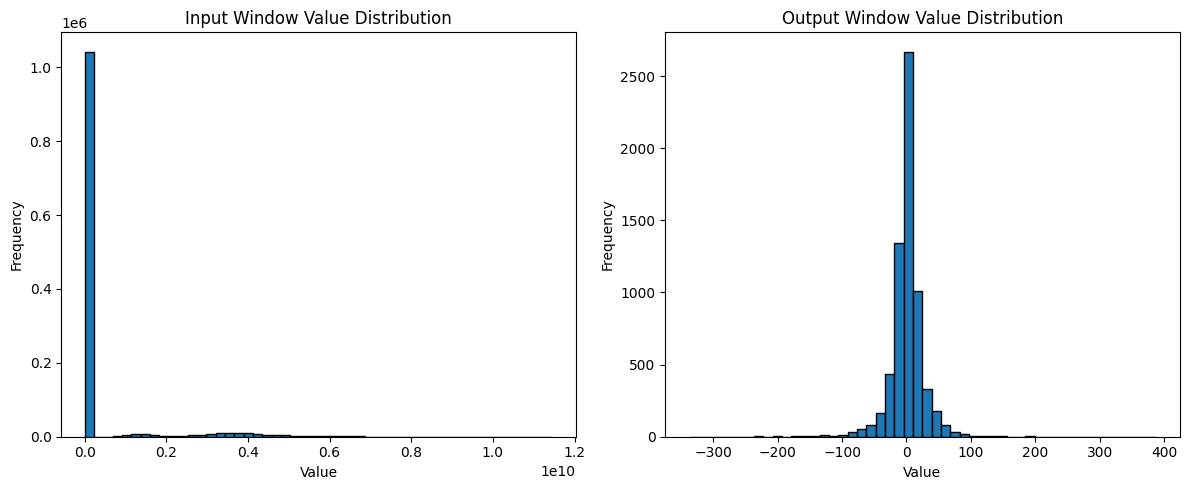

In [87]:
import math
in_lag = 20
out_lag = 1
in_features = ['Open','High','Low','Close','Day_sin','Day_cos','Month_sin','Month_cos', 'Volume']
out_features = ['Open','High','Low','Close']

def plot_windows(x, y):
    x_values = x.flatten()
    y_values = y.flatten()
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.hist(x_values, bins=50, edgecolor='black')
    plt.title('Input Window Value Distribution')
    plt.xlabel('Value')
    plt.ylabel('Frequency')

    plt.subplot(1, 2, 2)
    plt.hist(y_values, bins=50, edgecolor='black')
    plt.title('Output Window Value Distribution')
    plt.xlabel('Value')
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

def make_windows(in_col, out_col, in_lag, out_lag):
    x, y = [], []
    for i in range(len(in_col) - in_lag - out_lag):
        x.append(in_col[i:i+in_lag])
        y.append(out_col[i+in_lag:i+in_lag+out_lag])
    return np.array(x), np.array(y)
    
window_x, window_y = make_windows(df[in_features], df['Open_diff1'], in_lag, out_lag)
plot_windows(window_x, window_y)

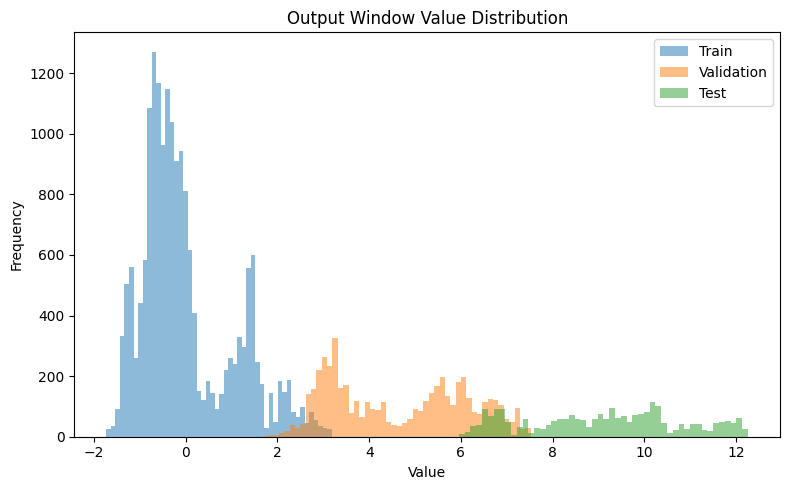

In [89]:
norm_cols = list(set(in_features + out_features))

def split_time_series(col, train_ratio=0.7, val_ratio=0.2):
    n = len(col)
    train_end = int(n * train_ratio)
    val_end   = int(n * (train_ratio + val_ratio))

    train = col[:train_end]
    val   = col[train_end:val_end]
    test  = col[val_end:]

    return train, val, test
    
def zscore_by_columns(train, val, test, cols):
    mean = train[cols].mean()
    std  = train[cols].std()

    train_n = train.copy()
    val_n   = val.copy()
    test_n  = test.copy()

    train_n[cols] = (train[cols] - mean) / std
    val_n[cols]   = (val[cols]   - mean) / std
    test_n[cols]  = (test[cols]  - mean) / std

    return train_n, val_n, test_n, mean, std
    
def plot_output_histograms(train_y, val_y, test_y):
    plt.figure(figsize=(8,5))

    plt.hist(train_y.flatten(), bins=50, alpha=0.5, label='Train')
    plt.hist(val_y.flatten(),   bins=50, alpha=0.5, label='Validation')
    plt.hist(test_y.flatten(),  bins=50, alpha=0.5, label='Test')

    plt.legend()
    plt.title('Output Window Value Distribution')
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

train_df, val_df, test_df = split_time_series(df)
train_n, val_n, test_n, mean, std = zscore_by_columns(
    train_df, val_df, test_df,
    norm_cols
)
out_means = mean[out_features]
out_stds = std[out_features]
train_x, train_y = make_windows(
    train_n[in_features].values,
    train_n[out_features].values,
    in_lag,
    out_lag
)

val_x, val_y = make_windows(
    val_n[in_features].values,
    val_n[out_features].values,
    in_lag,
    out_lag
)

test_x, test_y = make_windows(
    test_n[in_features].values,
    test_n[out_features].values,
    in_lag,
    out_lag
)

plot_output_histograms(train_y, val_y, test_y)

In [90]:
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
import torch

batch_size = 32

train_dataset = TensorDataset(
    torch.tensor(train_x, dtype=torch.float32),
    torch.tensor(train_y, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(val_x, dtype=torch.float32),
    torch.tensor(val_y, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(test_x, dtype=torch.float32),
    torch.tensor(test_y, dtype=torch.float32)
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [91]:
import torch.nn as nn
import torch.optim as optim

class MLPBaseline(nn.Module):
    def __init__(self, in_window=5, out_window=5, in_features=4, out_features=4):
        super(MLPBaseline, self).__init__()
        self.block = nn.Sequential(
            nn.Linear(in_features*in_window, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, out_features*out_window)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.block(x)
    
base_model = MLPBaseline(in_lag, out_lag, len(in_features), len(out_features))
criterion = nn.MSELoss()
optimizer = optim.AdamW(base_model.parameters(), lr=1e-3, weight_decay=1e-4)
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'


100%|██████████| 143/143 [00:00<00:00, 429.99it/s]


------------------------------Epoch Summary------------------------------
Epoch 1, Train Loss: 0.1431, Val Loss: 0.1459
Train Metrics: {'R2': np.float32(0.85725975), 'MAE': np.float32(0.26637846), 'RMSE': np.float32(0.37827146), 'MAPE': np.float32(265.0872)}
Validation Metrics: {'R2': np.float32(0.9320659), 'MAE': np.float32(0.32426992), 'RMSE': np.float32(0.3819966), 'MAPE': np.float32(7.2859564)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 443.73it/s]


------------------------------Epoch Summary------------------------------
Epoch 11, Train Loss: 0.0570, Val Loss: 0.0468
Train Metrics: {'R2': np.float32(0.94311947), 'MAE': np.float32(0.1765589), 'RMSE': np.float32(0.23878786), 'MAPE': np.float32(191.9049)}
Validation Metrics: {'R2': np.float32(0.9782083), 'MAE': np.float32(0.17106195), 'RMSE': np.float32(0.21635205), 'MAPE': np.float32(3.800223)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 442.23it/s]


------------------------------Epoch Summary------------------------------
Epoch 21, Train Loss: 0.0518, Val Loss: 0.0994
Train Metrics: {'R2': np.float32(0.9483067), 'MAE': np.float32(0.16833457), 'RMSE': np.float32(0.2276395), 'MAPE': np.float32(172.22112)}
Validation Metrics: {'R2': np.float32(0.95373356), 'MAE': np.float32(0.26992393), 'RMSE': np.float32(0.3152453), 'MAPE': np.float32(5.7089796)}
-------------------------------------------------------------------------


... (2 outputs left out)

100%|██████████| 143/143 [00:00<00:00, 439.14it/s]


------------------------------Epoch Summary------------------------------
Epoch 41, Train Loss: 0.0489, Val Loss: 0.5619
Train Metrics: {'R2': np.float32(0.95125043), 'MAE': np.float32(0.16786927), 'RMSE': np.float32(0.2210628), 'MAPE': np.float32(221.77972)}
Validation Metrics: {'R2': np.float32(0.73840946), 'MAE': np.float32(0.6942722), 'RMSE': np.float32(0.74959475), 'MAPE': np.float32(14.602521)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 432.18it/s]


------------------------------Epoch Summary------------------------------
Epoch 50, Train Loss: 0.0501, Val Loss: 0.3365
Train Metrics: {'R2': np.float32(0.95001924), 'MAE': np.float32(0.16744104), 'RMSE': np.float32(0.22383702), 'MAPE': np.float32(241.55032)}
Validation Metrics: {'R2': np.float32(0.8433638), 'MAE': np.float32(0.5389336), 'RMSE': np.float32(0.58004487), 'MAPE': np.float32(11.620693)}
-------------------------------------------------------------------------
Best model saved at epoch 20 with Validation Loss: 0.0301
Total training time: 0 minutes and 18 seconds


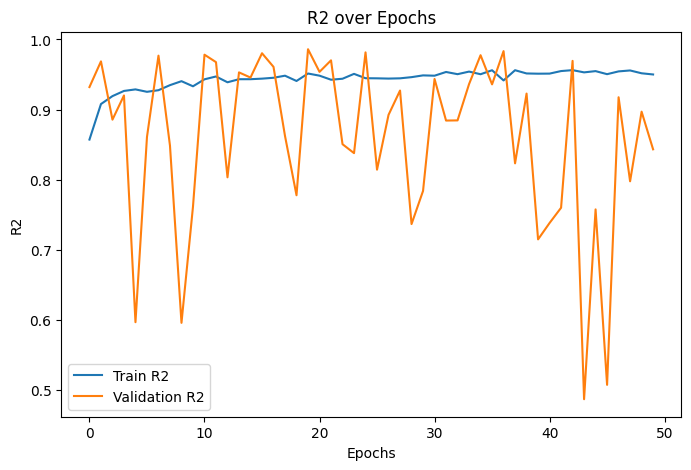

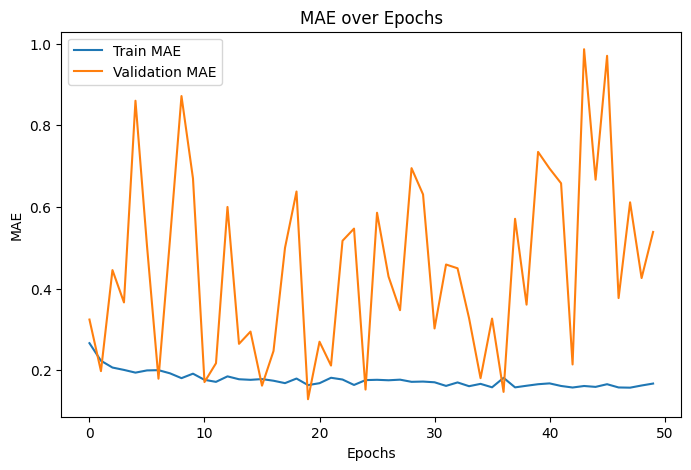

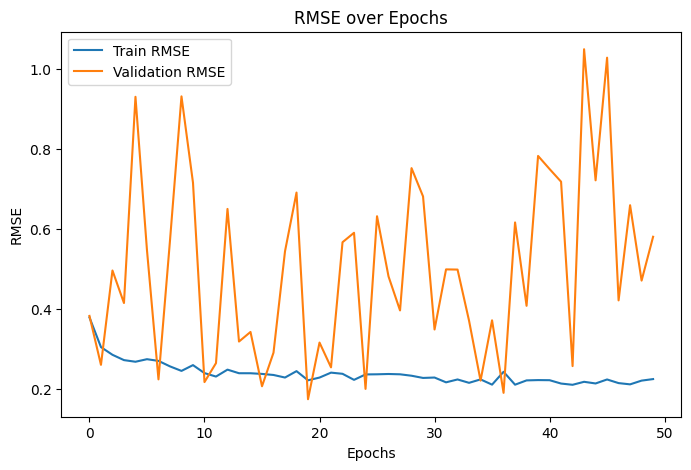

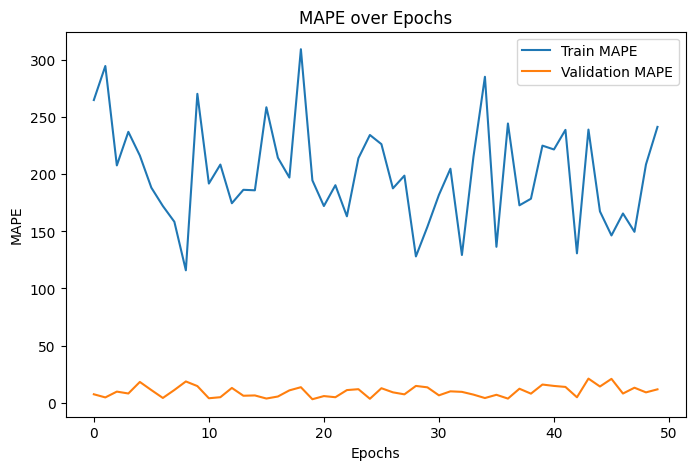

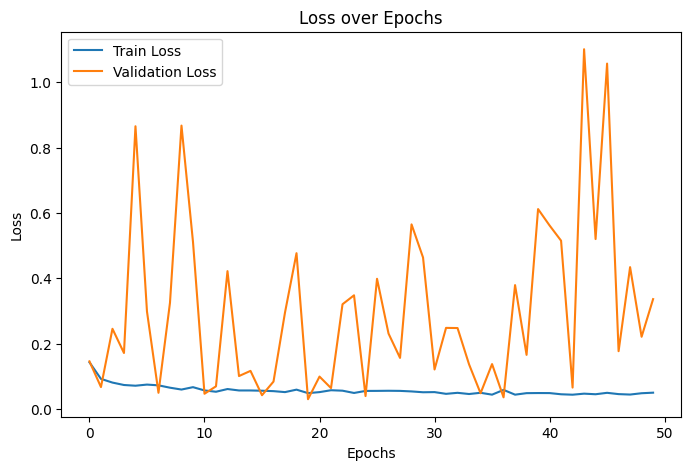

Test Metrics: {'R2': np.float64(0.9695440559932423), 'MAE': np.float64(108.85363973703782), 'RMSE': np.float64(131.4159862422095), 'MAPE': np.float64(1.9363166975084958)}


In [92]:
import tqdm
import time
def metrics_report(true, pred):
    R2 = 1 - np.sum((true - pred) ** 2) / np.sum((true - np.mean(true)) ** 2)
    MAE = np.mean(np.abs(true - pred))
    RMSE = np.sqrt(np.mean((true - pred) ** 2))
    eps = 1e-8
    MAPE = np.mean(np.abs((true - pred) / (true + eps))) * 100
    return {
        'R2': R2,
        'MAE': MAE,
        'RMSE': RMSE,
        'MAPE': MAPE
    }

def plot_all_metrics(train_history, val_history):
    metrics = train_history[0].keys()
    for metric in metrics:
        plt.figure(figsize=(8,5))
        plt.plot([h[metric] for h in train_history], label=f'Train {metric}')
        plt.plot([h[metric] for h in val_history], label=f'Validation {metric}')
        plt.title(f'{metric} over Epochs')
        plt.xlabel('Epochs')
        plt.ylabel(metric)
        plt.legend()

def plot_losses(train_loss, val_loss):
    plt.figure(figsize=(8,5))
    plt.plot(train_loss, label='Train Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

def test_model(model, model_path, test_loader, device='cuda:0'):
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    model.eval()

    all_test_true, all_test_pred = [], []
    with torch.no_grad():
        for inputs, targets in test_loader:
            if inputs.dim() == 3:
                inputs = inputs.float().to(device)
            else:
                inputs = inputs.view(inputs.size(0), -1).float().to(device)
            
            targets = targets.view(targets.size(0), -1).float().to(device)

            outputs = model(inputs)

            all_test_true.append(targets.cpu().numpy())
            all_test_pred.append(outputs.cpu().numpy())

    all_test_true = np.vstack(all_test_true)
    all_test_pred = np.vstack(all_test_pred)
    all_test_true = all_test_true * out_stds.values + out_means.values
    all_test_pred = all_test_pred * out_stds.values + out_means.values
    test_metrics = metrics_report(all_test_true, all_test_pred)
    print('Test Metrics:', test_metrics)
    test_metrics

def train_model(model, train_loader, val_loader, criterion, optimizer,
                epochs=50, save_path='best_model.pth', device='cuda:0'):
    model.to(device)
    best_val_loss = float('inf')
    val_metrics_history = []
    val_loss_history = []
    train_metrics_history = []
    train_loss_history = []
    
    total_start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        all_train_true, all_train_pred = [], []
        
        for inputs, targets in tqdm.tqdm(train_loader):
            if inputs.dim() == 3:
                inputs = inputs.float().to(device)
            else:
                inputs = inputs.view(inputs.size(0), -1).float().to(device)
           
            targets = targets.view(targets.size(0), -1).float().to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            all_train_true.append(targets.detach().cpu().numpy())
            all_train_pred.append(outputs.detach().cpu().numpy())
        
        train_loss /= len(train_loader.dataset)
        train_loss_history.append(train_loss)
        all_train_true = np.vstack(all_train_true)
        all_train_pred = np.vstack(all_train_pred)
        train_metrics = metrics_report(all_train_true, all_train_pred)
        train_metrics_history.append(train_metrics)
        
        model.eval()
        val_loss = 0.0
        all_val_true, all_val_pred = [], []
        with torch.no_grad():
            for inputs, targets in val_loader:
                if inputs.dim() == 3:
                    inputs = inputs.float().to(device)
                else:
                    inputs = inputs.view(inputs.size(0), -1).float().to(device)
                   
                targets = targets.view(targets.size(0), -1).float().to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                all_val_true.append(targets.cpu().numpy())
                all_val_pred.append(outputs.cpu().numpy())
        
        val_loss /= len(val_loader.dataset)
        all_val_true = np.vstack(all_val_true)
        all_val_pred = np.vstack(all_val_pred)
        val_metrics = metrics_report(all_val_true, all_val_pred)
        val_metrics_history.append(val_metrics)
        val_loss_history.append(val_loss)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            best_epoch = epoch + 1
        
        if epoch % 10 == 0 or epoch == epochs - 1:
            print('------------------------------Epoch Summary------------------------------')
            print(f'Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')
            print('Train Metrics:', train_metrics)
            print('Validation Metrics:', val_metrics)
            print('-------------------------------------------------------------------------')
    
    total_end_time = time.time()
    total_time = total_end_time - total_start_time
    minutes = int(total_time // 60)
    seconds = int(total_time % 60)
    
    print(f"Best model saved at epoch {best_epoch} with Validation Loss: {best_val_loss:.4f}")
    print(f"Total training time: {minutes} minutes and {seconds} seconds")
    
    plot_all_metrics(train_metrics_history, val_metrics_history)
    plot_losses(train_loss_history, val_loss_history)
    
    return save_path, total_time

base_path, base_time = train_model(base_model, train_loader, val_loader, criterion, optimizer, epochs=50, save_path='base_model.pth')

test_model(base_model, 
               base_path, test_loader)


In [93]:
class CNN_LSTM(nn.Module):
    def __init__(self,
                 in_features=9,
                 conv_channels=64,
                 kernel_size=3,
                 hidden_size=512,
                 out_features=4):
        super().__init__()
        self.conv = nn.Conv1d(
            in_channels=in_features,
            out_channels=conv_channels,
            kernel_size=kernel_size
        )
        self.lstm = nn.LSTM(
            input_size=conv_channels,
            hidden_size=hidden_size,
            batch_first=True,
            num_layers=1
        )
        self.fc1 = nn.Linear(hidden_size, 256)
        self.fc2 = nn.Linear(256, out_features)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.conv(x)      
        x = x.permute(0, 2, 1)
        
        x, _ = self.lstm(x)   
        x = x[:, -1, :]       
        
        x = self.relu(self.fc1(x))
        out = self.fc2(x)         
        return out

100%|██████████| 143/143 [00:00<00:00, 240.36it/s]


------------------------------Epoch Summary------------------------------
Epoch 1, Train Loss: 0.0372, Val Loss: 1.7545
Train Metrics: {'R2': np.float32(0.962906), 'MAE': np.float32(0.0873861), 'RMSE': np.float32(0.19283333), 'MAPE': np.float32(63.871296)}
Validation Metrics: {'R2': np.float32(0.18319637), 'MAE': np.float32(0.9809026), 'RMSE': np.float32(1.3245684), 'MAPE': np.float32(17.128407)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 262.73it/s]


------------------------------Epoch Summary------------------------------
Epoch 11, Train Loss: 0.0012, Val Loss: 0.2256
Train Metrics: {'R2': np.float32(0.99878126), 'MAE': np.float32(0.025323749), 'RMSE': np.float32(0.0349532), 'MAPE': np.float32(24.803295)}
Validation Metrics: {'R2': np.float32(0.89494926), 'MAE': np.float32(0.35924992), 'RMSE': np.float32(0.47502354), 'MAPE': np.float32(6.560322)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 271.11it/s]


------------------------------Epoch Summary------------------------------
Epoch 21, Train Loss: 0.0011, Val Loss: 0.0894
Train Metrics: {'R2': np.float32(0.9989101), 'MAE': np.float32(0.023692919), 'RMSE': np.float32(0.03305319), 'MAPE': np.float32(19.06668)}
Validation Metrics: {'R2': np.float32(0.9583839), 'MAE': np.float32(0.2147991), 'RMSE': np.float32(0.2989828), 'MAPE': np.float32(3.9107897)}
-------------------------------------------------------------------------


... (2 outputs left out)

100%|██████████| 143/143 [00:00<00:00, 271.42it/s]


------------------------------Epoch Summary------------------------------
Epoch 41, Train Loss: 0.0009, Val Loss: 0.0658
Train Metrics: {'R2': np.float32(0.99914235), 'MAE': np.float32(0.020956473), 'RMSE': np.float32(0.029321874), 'MAPE': np.float32(19.16007)}
Validation Metrics: {'R2': np.float32(0.96935076), 'MAE': np.float32(0.1997619), 'RMSE': np.float32(0.2565816), 'MAPE': np.float32(3.845891)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:00<00:00, 274.97it/s]


------------------------------Epoch Summary------------------------------
Epoch 50, Train Loss: 0.0008, Val Loss: 0.0157
Train Metrics: {'R2': np.float32(0.99920756), 'MAE': np.float32(0.020052109), 'RMSE': np.float32(0.028185189), 'MAPE': np.float32(22.393196)}
Validation Metrics: {'R2': np.float32(0.9926771), 'MAE': np.float32(0.09669263), 'RMSE': np.float32(0.12541741), 'MAPE': np.float32(2.321366)}
-------------------------------------------------------------------------
Best model saved at epoch 50 with Validation Loss: 0.0157
Total training time: 0 minutes and 29 seconds


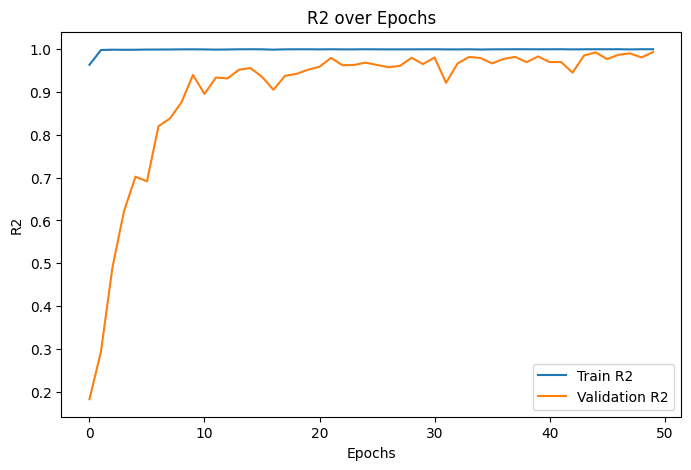

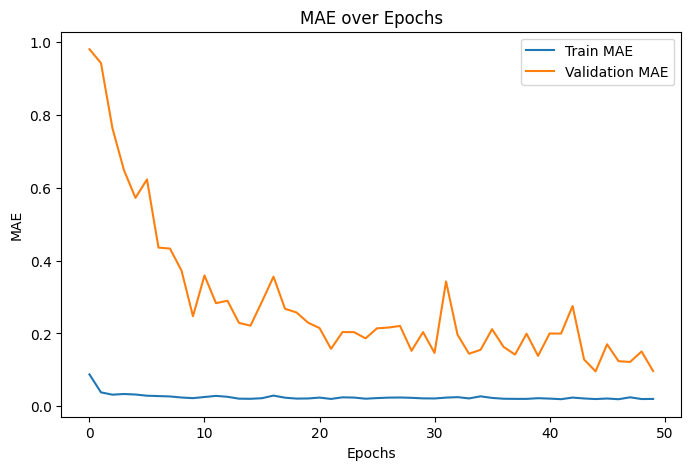

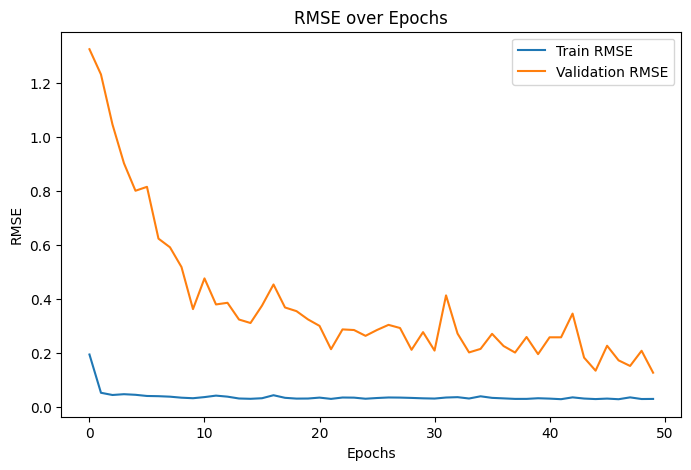

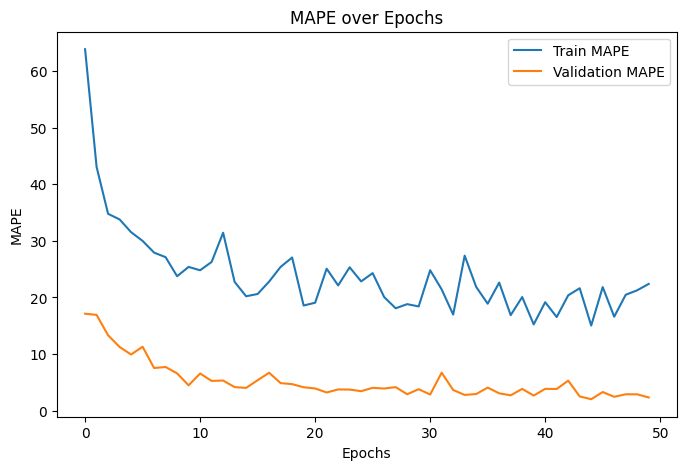

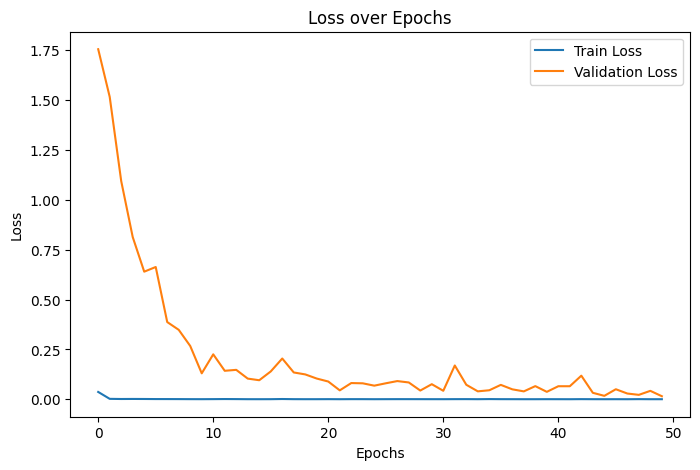

In [94]:
model_lstm = CNN_LSTM()

optimizer = optim.AdamW(model_lstm.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

lstm_path, lstm_time = train_model(
    model_lstm,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=50,
    save_path="cnn_lstm.pth"
)

In [95]:
class CNN_GRU(nn.Module):
    def __init__(self,
                 in_features=9,
                 conv_channels=64,
                 kernel_size=7,  
                 hidden_size=512,
                 gru_layers=4,  
                 out_features=4,
                 dropout=0.3):  
        super().__init__()
        self.conv = nn.Conv1d(
            in_channels=in_features,
            out_channels=conv_channels,
            kernel_size=kernel_size,
            padding=kernel_size//2 
        )
        self.gru = nn.GRU(
            input_size=conv_channels,
            hidden_size=hidden_size,
            num_layers=gru_layers,
            batch_first=True,
            dropout=dropout if gru_layers > 1 else 0
        )
        
        self.fc1 = nn.Linear(hidden_size + conv_channels, 256)
        self.fc2 = nn.Linear(256, out_features)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x_conv = x.permute(0, 2, 1)
        x_conv = self.conv(x_conv) 
        x_conv_t = x_conv.permute(0, 2, 1)
        
        gru_out, _ = self.gru(x_conv_t)
        h_last = gru_out[:, -1, :]     
        
        conv_mean = x_conv_t.mean(dim=1)
        x_res = torch.cat([h_last, conv_mean], dim=1)
        
        x = self.dropout(self.relu(self.fc1(x_res)))
        out = self.fc2(x)
        return out

100%|██████████| 143/143 [00:01<00:00, 83.80it/s]


------------------------------Epoch Summary------------------------------
Epoch 1, Train Loss: 0.0557, Val Loss: 0.1637
Train Metrics: {'R2': np.float32(0.94441134), 'MAE': np.float32(0.14203352), 'RMSE': np.float32(0.23606056), 'MAPE': np.float32(117.26871)}
Validation Metrics: {'R2': np.float32(0.9237959), 'MAE': np.float32(0.34202373), 'RMSE': np.float32(0.4045803), 'MAPE': np.float32(7.5565996)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:01<00:00, 82.51it/s]


------------------------------Epoch Summary------------------------------
Epoch 11, Train Loss: 0.0107, Val Loss: 0.3378
Train Metrics: {'R2': np.float32(0.9893138), 'MAE': np.float32(0.07598624), 'RMSE': np.float32(0.103500366), 'MAPE': np.float32(49.17456)}
Validation Metrics: {'R2': np.float32(0.8427138), 'MAE': np.float32(0.51676285), 'RMSE': np.float32(0.58124727), 'MAPE': np.float32(11.542143)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:01<00:00, 81.57it/s]


------------------------------Epoch Summary------------------------------
Epoch 21, Train Loss: 0.0086, Val Loss: 0.0748
Train Metrics: {'R2': np.float32(0.9914613), 'MAE': np.float32(0.066901274), 'RMSE': np.float32(0.092518285), 'MAPE': np.float32(47.255943)}
Validation Metrics: {'R2': np.float32(0.96517295), 'MAE': np.float32(0.22742838), 'RMSE': np.float32(0.27351052), 'MAPE': np.float32(5.1156564)}
-------------------------------------------------------------------------


... (2 outputs left out)

100%|██████████| 143/143 [00:01<00:00, 79.46it/s]


------------------------------Epoch Summary------------------------------
Epoch 41, Train Loss: 0.0074, Val Loss: 0.0618
Train Metrics: {'R2': np.float32(0.9926455), 'MAE': np.float32(0.060571734), 'RMSE': np.float32(0.085863), 'MAPE': np.float32(40.580307)}
Validation Metrics: {'R2': np.float32(0.97123885), 'MAE': np.float32(0.2070153), 'RMSE': np.float32(0.24855275), 'MAPE': np.float32(4.672189)}
-------------------------------------------------------------------------


100%|██████████| 143/143 [00:01<00:00, 78.83it/s]


------------------------------Epoch Summary------------------------------
Epoch 50, Train Loss: 0.0068, Val Loss: 0.0323
Train Metrics: {'R2': np.float32(0.9932072), 'MAE': np.float32(0.058070667), 'RMSE': np.float32(0.08251901), 'MAPE': np.float32(43.85512)}
Validation Metrics: {'R2': np.float32(0.9849597), 'MAE': np.float32(0.13723582), 'RMSE': np.float32(0.17973943), 'MAPE': np.float32(3.1629972)}
-------------------------------------------------------------------------
Best model saved at epoch 33 with Validation Loss: 0.0278
Total training time: 1 minutes and 37 seconds


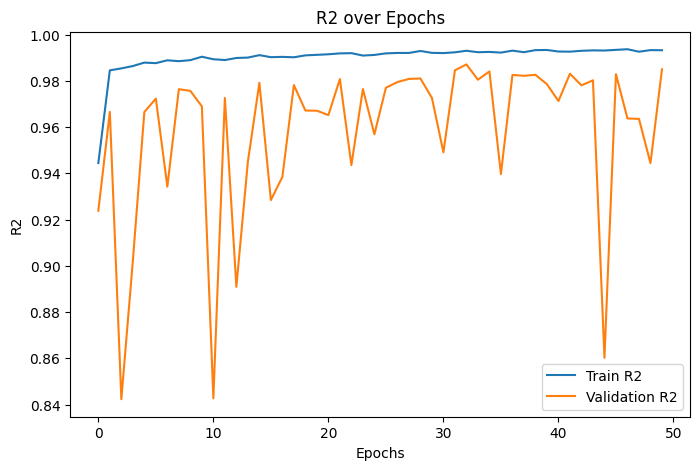

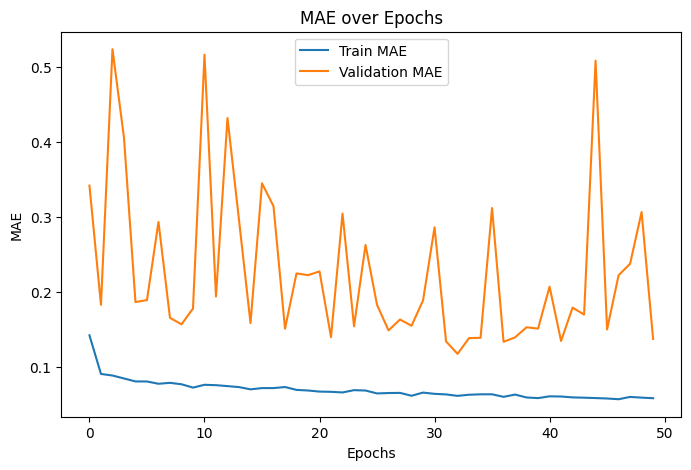

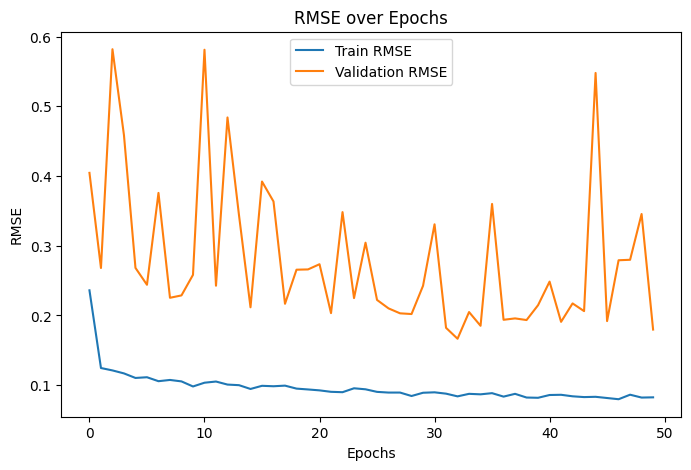

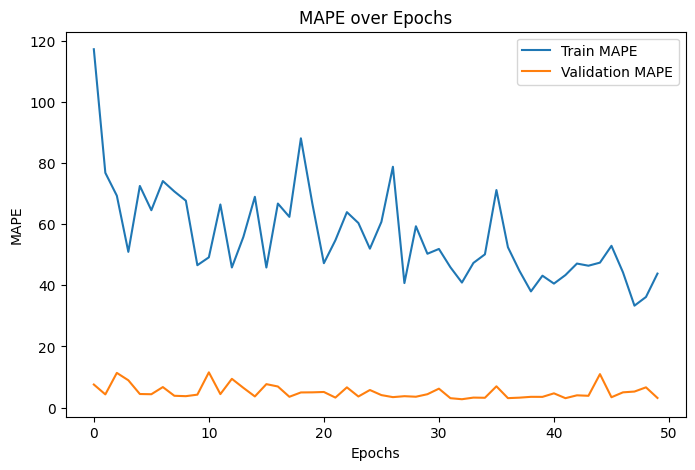

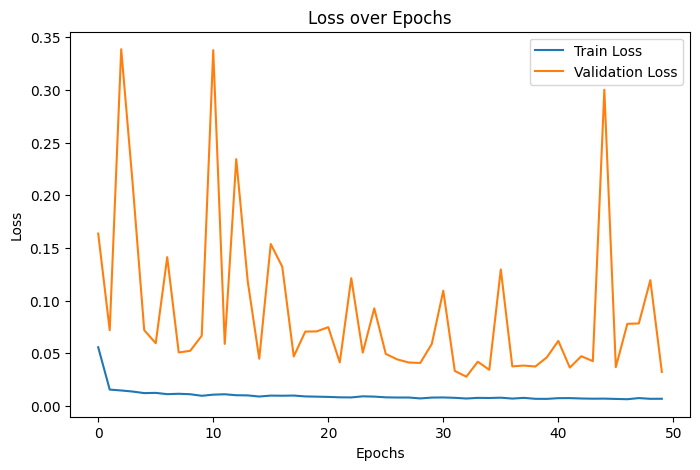

In [96]:
model_gru = CNN_GRU()

optimizer = optim.AdamW(model_gru.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

gru_path, gru_time = train_model(
    model_gru,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=50,
    save_path="cnn_gru.pth"
)


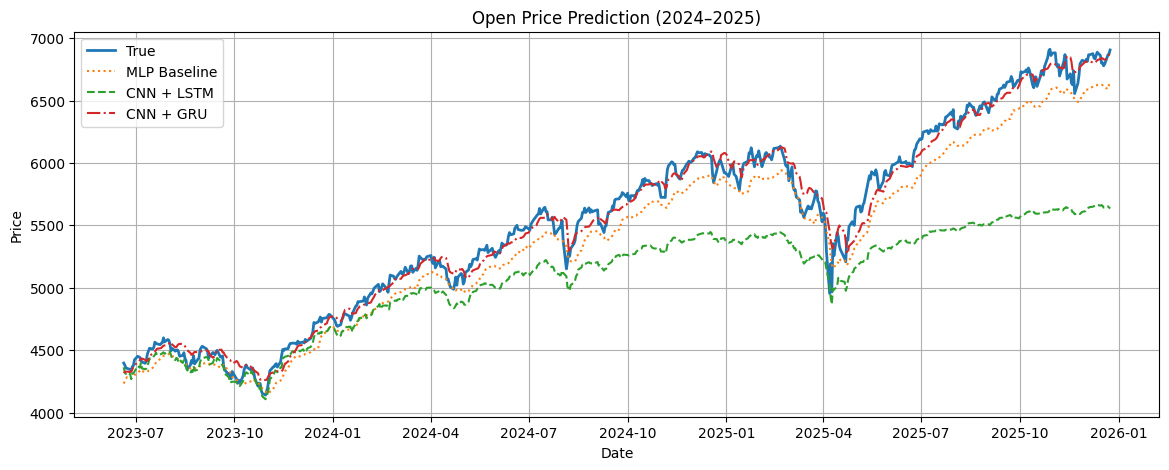


Open Metrics:
MLP Baseline: {'R2': np.float64(0.9447310539911644), 'MAE': np.float64(158.5882358041305), 'RMSE': np.float64(177.1319662592214), 'MAPE': np.float64(2.802992732391487)}
CNN + LSTM   : {'R2': np.float64(0.4220444162893058), 'MAE': np.float64(452.6845279384703), 'RMSE': np.float64(572.8007582589267), 'MAPE': np.float64(7.513446147859687)}
CNN + GRU    : {'R2': np.float64(0.9869509888474228), 'MAE': np.float64(64.14571653291031), 'RMSE': np.float64(86.0686821811659), 'MAPE': np.float64(1.1828782342151072)}


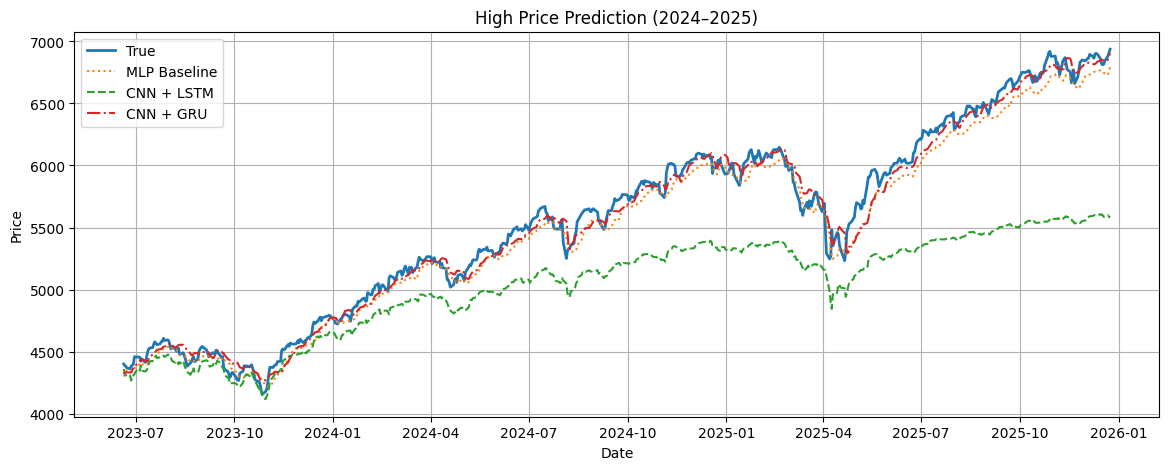


High Metrics:
MLP Baseline: {'R2': np.float64(0.9788638773399959), 'MAE': np.float64(92.83528781970652), 'RMSE': np.float64(109.77235580460056), 'MAPE': np.float64(1.6401196979199173)}
CNN + LSTM   : {'R2': np.float64(0.2939210115885763), 'MAE': np.float64(517.1013302472903), 'RMSE': np.float64(634.4639756648849), 'MAPE': np.float64(8.610566155757661)}
CNN + GRU    : {'R2': np.float64(0.9874357196266019), 'MAE': np.float64(66.4952423464717), 'RMSE': np.float64(84.63483149717914), 'MAPE': np.float64(1.2146335130743102)}


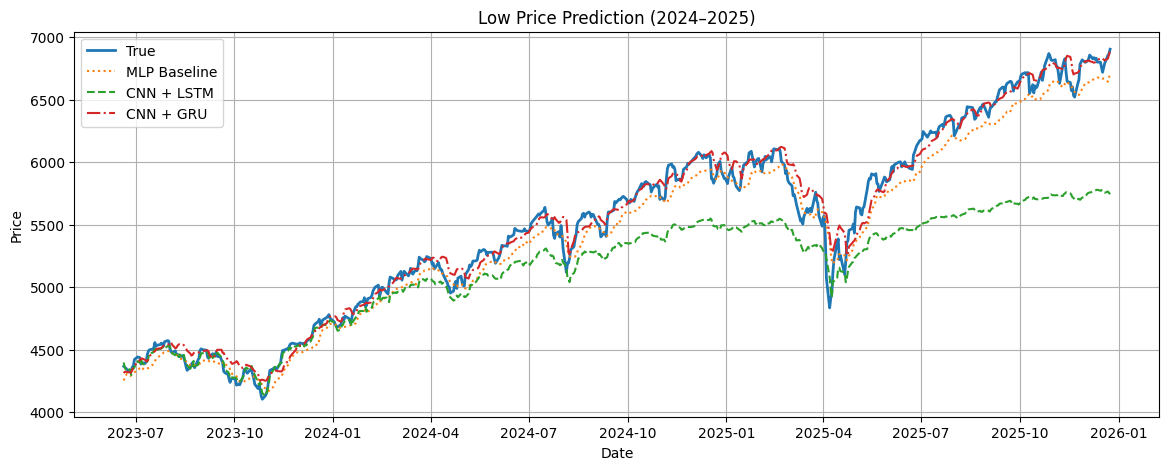


Low Metrics:
MLP Baseline: {'R2': np.float64(0.9696030440268556), 'MAE': np.float64(110.69889141833237), 'RMSE': np.float64(130.72036923291404), 'MAPE': np.float64(1.977286317403463)}
CNN + LSTM   : {'R2': np.float64(0.596990286027046), 'MAE': np.float64(353.10866670557317), 'RMSE': np.float64(475.97700924167816), 'MAPE': np.float64(5.804615373594932)}
CNN + GRU    : {'R2': np.float64(0.983292205942822), 'MAE': np.float64(68.07759880849845), 'RMSE': np.float64(96.91428039422149), 'MAPE': np.float64(1.2743705924734554)}


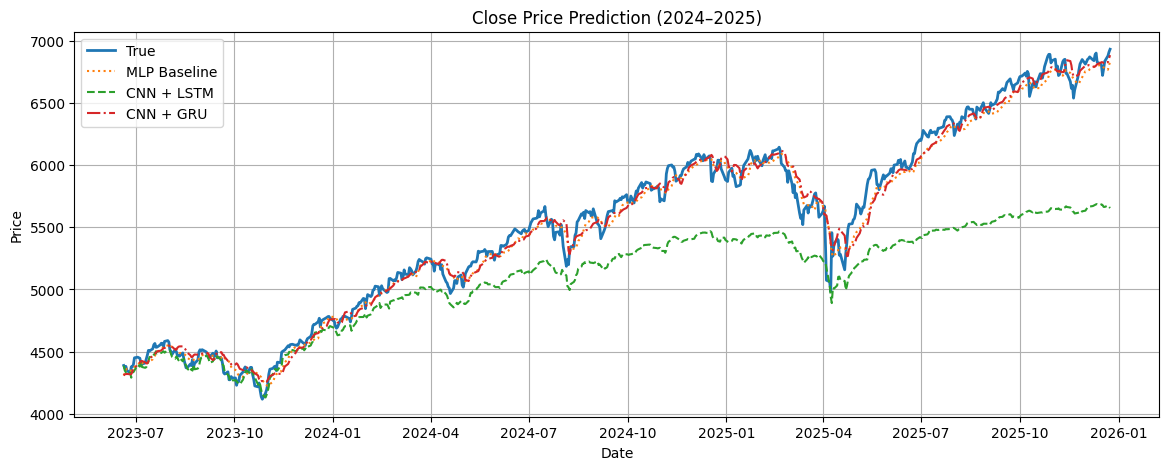


Close Metrics:
MLP Baseline: {'R2': np.float64(0.9848831448979556), 'MAE': np.float64(73.29214982575532), 'RMSE': np.float64(92.55879552883049), 'MAPE': np.float64(1.3248680522729908)}
CNN + LSTM   : {'R2': np.float64(0.45179897021702076), 'MAE': np.float64(433.9712485714739), 'RMSE': np.float64(557.3870737356829), 'MAPE': np.float64(7.173086986270164)}
CNN + GRU    : {'R2': np.float64(0.9837017183249555), 'MAE': np.float64(74.22098423031703), 'RMSE': np.float64(96.10763248035825), 'MAPE': np.float64(1.3641596506706055)}


In [108]:
def plot_price_predictions(
    base_model, lstm_model, gru_model,
    test_x, test_y, dates, device,
    out_means, out_stds
):
    base_preds = predict_model(base_model, test_x, device)
    lstm_preds = predict_model(lstm_model, test_x, device)
    gru_preds = predict_model(gru_model, test_x, device)

    true_prices = test_y.reshape(-1, len(out_features)) * out_stds.values + out_means.values
    base_preds = base_preds * out_stds.values + out_means.values
    lstm_preds = lstm_preds * out_stds.values + out_means.values
    gru_preds = gru_preds * out_stds.values + out_means.values

    price_names = ["Open", "High", "Low", "Close"]

    for i, name in enumerate(price_names):
        plt.figure(figsize=(14, 5))
        plt.plot(dates, true_prices[:, i], label="True", linewidth=2)
        plt.plot(dates, base_preds[:, i], label="MLP Baseline", linestyle=":")
        plt.plot(dates, lstm_preds[:, i], label="CNN + LSTM", linestyle="--")
        plt.plot(dates, gru_preds[:, i], label="CNN + GRU", linestyle="-.")
        plt.title(f"{name} Price Prediction (2024–2025)")
        plt.xlabel("Date")
        plt.ylabel("Price")
        plt.legend()
        plt.grid(True)
        plt.show()

        print(f"\n{name} Metrics:")
        print("MLP Baseline:", metrics_report(true_prices[:, i], base_preds[:, i]))
        print("CNN + LSTM   :", metrics_report(true_prices[:, i], lstm_preds[:, i]))
        print("CNN + GRU    :", metrics_report(true_prices[:, i], gru_preds[:, i]))

plot_price_predictions(
    base_model, model_lstm, model_gru,
    test_x, test_y, test_dates, device,
    out_means, out_stds
)

In [101]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

base_params = count_parameters(base_model)
lstm_params = count_parameters(model_lstm)
gru_params  = count_parameters(model_gru)

print("Model Parameters Count")
print("----------------------")
print(f"MLP Baseline : {base_params:,}")
print(f"CNN + LSTM   : {lstm_params:,}")
print(f"CNN + GRU    : {gru_params:,}")

Model Parameters Count
----------------------
MLP Baseline : 32,068
CNN + LSTM   : 1,317,892
CNN + GRU    : 5,768,452


In [102]:
from torchinfo import summary

print("CNN + LSTM Summary")
summary(CNN_LSTM(), input_size=(batch_size, in_lag, 9))



CNN + LSTM Summary


Layer (type:depth-idx)                   Output Shape              Param #
CNN_LSTM                                 [32, 4]                   --
├─Conv1d: 1-1                            [32, 64, 18]              1,792
├─LSTM: 1-2                              [32, 18, 512]             1,183,744
├─Linear: 1-3                            [32, 256]                 131,328
├─ReLU: 1-4                              [32, 256]                 --
├─Linear: 1-5                            [32, 4]                   1,028
Total params: 1,317,892
Trainable params: 1,317,892
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 687.10
Input size (MB): 0.02
Forward/backward pass size (MB): 2.72
Params size (MB): 5.27
Estimated Total Size (MB): 8.02

In [103]:
print("\nCNN + GRU Summary")
summary(CNN_GRU(), input_size=(batch_size, in_lag, 9))


CNN + GRU Summary


Layer (type:depth-idx)                   Output Shape              Param #
CNN_GRU                                  [32, 4]                   --
├─Conv1d: 1-1                            [32, 64, 20]              4,096
├─GRU: 1-2                               [32, 20, 512]             5,615,616
├─Linear: 1-3                            [32, 256]                 147,712
├─ReLU: 1-4                              [32, 256]                 --
├─Dropout: 1-5                           [32, 256]                 --
├─Linear: 1-6                            [32, 4]                   1,028
Total params: 5,768,452
Trainable params: 5,768,452
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 3.60
Input size (MB): 0.02
Forward/backward pass size (MB): 3.02
Params size (MB): 23.07
Estimated Total Size (MB): 26.11

In [104]:
models = {
    'MLP Baseline': (base_model, 'base_model.pth'),
    'CNN + LSTM': (model_lstm, 'cnn_lstm.pth'),
    'CNN + GRU': (model_gru, 'cnn_gru.pth')
}

metrics_dict = {}
params_dict = {
    'MLP Baseline': base_params,
    'CNN + LSTM': lstm_params,
    'CNN + GRU': gru_params
}

for name, (model, path) in models.items():
    metrics = test_model(model, path, test_loader, device=device)
    metrics_dict[name] = metrics

results_df = pd.DataFrame.from_dict(metrics_dict, orient='index')
results_df['Parameters'] = params_dict.values()
print(results_df)

Test Metrics: {'R2': np.float64(0.9695440559932423), 'MAE': np.float64(108.85363973703782), 'RMSE': np.float64(131.4159862422095), 'MAPE': np.float64(1.9363166975084958)}
Test Metrics: {'R2': np.float64(0.44102327154414467), 'MAE': np.float64(439.21645251289965), 'RMSE': np.float64(563.0008230665347), 'MAPE': np.float64(7.275428881551021)}
Test Metrics: {'R2': np.float64(0.9853629745503266), 'MAE': np.float64(68.23488892934614), 'RMSE': np.float64(91.10423798895977), 'MAPE': np.float64(1.259010549266204)}
                 0  Parameters
MLP Baseline  None       32068
CNN + LSTM    None     1317892
CNN + GRU     None     5768452


In [111]:
print("\nTraining Time Report (for 50 epochs):")
print(f"MLP Baseline: {int(base_time // 60)} minutes and {int(base_time % 60)} seconds")
print(f"CNN + LSTM   : {int(lstm_time // 60)} minutes and {int(lstm_time % 60)} seconds")
print(f"CNN + GRU    : {int(gru_time // 60)} minutes and {int(gru_time % 60)} seconds")

print("\nApproximate FLOPs (2 × number of parameters):")
flops_dict = {k: 2 * v for k, v in params_dict.items()}
for name, flops in flops_dict.items():
    print(f"{name}: {flops:,}")



Training Time Report (for 50 epochs):
MLP Baseline: 0 minutes and 18 seconds
CNN + LSTM   : 0 minutes and 29 seconds
CNN + GRU    : 1 minutes and 37 seconds

Approximate FLOPs (2 × number of parameters):
MLP Baseline: 64,136
CNN + LSTM: 2,635,784
CNN + GRU: 11,536,904


/tmp/ipykernel_55/4088993848.py:20: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  norm_volume_mean = float(train_n['Volume'].mean())


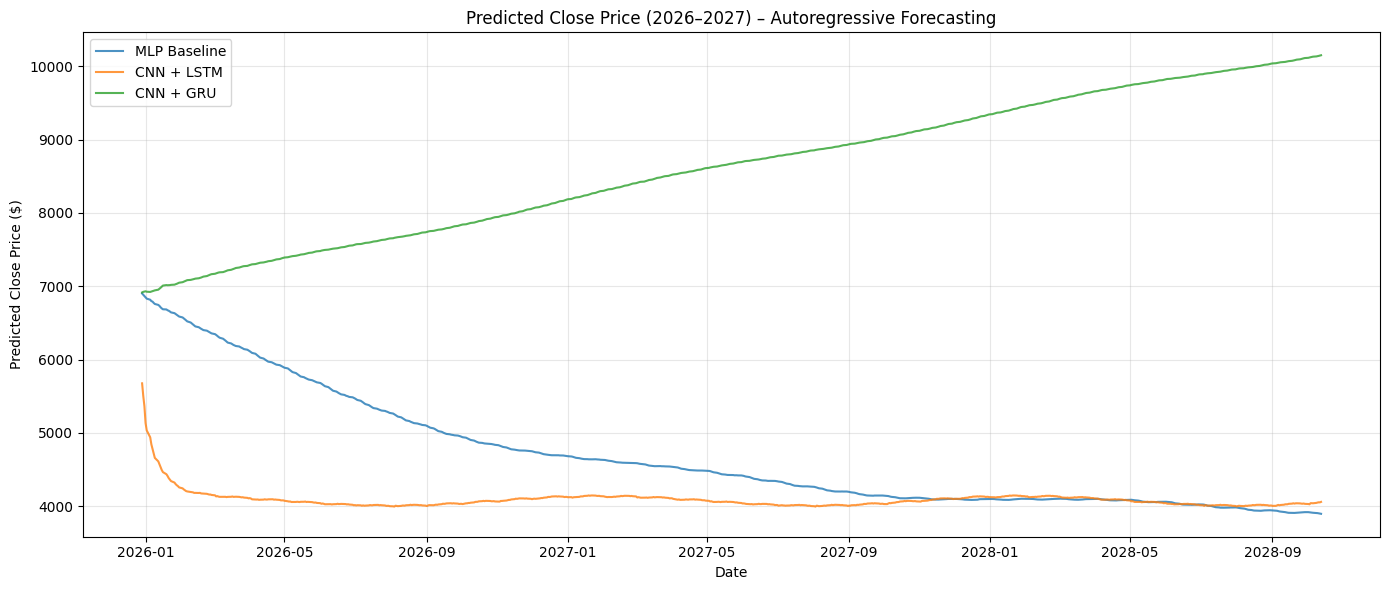

Steps: 730


In [129]:
base_model.eval()
model_lstm.eval()
model_gru.eval()

last_date = df.index[-1]
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=365*2,
    freq='B'
)

future_df = pd.DataFrame(index=future_dates)
future_df['Month'] = future_df.index.month
future_df['Day'] = future_df.index.day
future_df['Month_sin'] = np.sin(2 * np.pi * future_df['Month'] / 12)
future_df['Day_sin'] = np.sin(2 * np.pi * future_df['Day'] / 31)
future_df['Month_cos'] = np.cos(2 * np.pi * future_df['Month'] / 12)
future_df['Day_cos'] = np.cos(2 * np.pi * future_df['Day'] / 31)

norm_volume_mean = float(train_n['Volume'].mean())

def autoregressive_predict(model, last_window, future_df, out_means, out_stds, device, num_steps):
    predictions = []
    current_window = last_window.copy().astype(np.float32)
    for i in range(num_steps):
        input_tensor = torch.from_numpy(current_window[np.newaxis]).to(device)
        with torch.no_grad():
            pred_norm = model(input_tensor).detach().cpu().numpy()[0]
        pred_actual = pred_norm * out_stds.values + out_means.values
        predictions.append(pred_actual)
        
        time_features = np.array([
            future_df.iloc[i]['Day_sin'],
            future_df.iloc[i]['Day_cos'],
            future_df.iloc[i]['Month_sin'],
            future_df.iloc[i]['Month_cos'],
            norm_volume_mean
        ], dtype=np.float32)
        
        new_row = np.concatenate([pred_norm, time_features])
        current_window = np.vstack((current_window[1:], new_row))
    return np.array(predictions)

last_window = test_n[in_features].values[-in_lag:]
num_steps = len(future_dates)

base_future = autoregressive_predict(base_model, last_window, future_df, out_means, out_stds, device, num_steps)
lstm_future = autoregressive_predict(model_lstm, last_window, future_df, out_means, out_stds, device, num_steps)
gru_future = autoregressive_predict(model_gru, last_window, future_df, out_means, out_stds, device, num_steps)

plt.figure(figsize=(14, 6))
plt.plot(future_dates, base_future[:, 3], label="MLP Baseline", alpha=0.8)
plt.plot(future_dates, lstm_future[:, 3], label="CNN + LSTM", alpha=0.8)
plt.plot(future_dates, gru_future[:, 3], label="CNN + GRU", alpha=0.8)
plt.title("Predicted Close Price (2026–2027) – Autoregressive Forecasting")
plt.xlabel("Date")
plt.ylabel("Predicted Close Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Steps: {num_steps}")

In [132]:
def get_test_metrics(model, test_loader, device, out_means, out_stds):
    model.eval()
    all_true = []
    all_pred = []
    with torch.no_grad():
        for inputs, targets in test_loader:
            if inputs.dim() == 3:
                inputs = inputs.float().to(device)
            else:
                inputs = inputs.view(inputs.size(0), -1).float().to(device)
            targets = targets.view(targets.size(0), -1).float().to(device)
            outputs = model(inputs)
            all_true.append(targets.cpu().numpy())
            all_pred.append(outputs.cpu().numpy())
    all_true = np.vstack(all_true)
    all_pred = np.vstack(all_pred)
    
    all_true = all_true * out_stds.values + out_means.values
    all_pred = all_pred * out_stds.values + out_means.values
    
    metrics = metrics_report(all_true, all_pred)
    return metrics

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

base_model.load_state_dict(torch.load('base_model.pth', map_location=device))
model_lstm.load_state_dict(torch.load('cnn_lstm.pth', map_location=device))
model_gru.load_state_dict(torch.load('cnn_gru.pth', map_location=device))

base_model.to(device)
model_lstm.to(device)
model_gru.to(device)

metrics_dict = {}
params_dict = {}

for name, model in models.items():
    metrics = get_test_metrics(model, test_loader, device, out_means, out_stds)
    metrics_dict[name] = metrics
    params_dict[name] = count_parameters(model)

results_df = pd.DataFrame.from_dict(metrics_dict, orient='index')
results_df['Parameters'] = params_dict.values()
results_df = results_df[['R2', 'MAE', 'RMSE', 'MAPE', 'Parameters']]

print("Model Comparison on Test Data (Unseen):")
print(results_df)

Model Comparison on Test Data (Unseen):
                    R2         MAE        RMSE      MAPE  Parameters
MLP Baseline  0.969544  108.853640  131.415986  1.936317       32068
CNN + LSTM    0.441023  439.216453  563.000823  7.275429     1317892
CNN + GRU     0.985363   68.234889   91.104238  1.259011     5768452
